# 06 · Stage 2: square-root fits, the real threshold, the first critical rate and hysteresis loops

**Purpose.** Starts from the master table of switching points (notebook 05) and tests the square-root law on the bench: fits, model comparison against a fixed delay, free exponents, the threshold $G_c$ of the real circuit, the first critical rate, and the cycle-averaged hysteresis loops.

**In the report.** Chapter 5: Eqs. (5.1)–(5.4), Figs. 5.2–5.4, the coefficient comparison with Eq. (2.27), and Appendix Table A.1. With `MASTER_CSV` pointed at the simulation master it also gives the Stage 3 fits, Eqs. (6.1)–(6.2) (see notebook 09).

## Theory

For an $R_F$ sweep through threshold at rate $\lambda$ (notebook 00):

$$R_{\rm on} = R_c + k_{\rm on}\sqrt{\lambda}, \qquad R_{\rm off} = R_c - k_{\rm off}\sqrt{\lambda}, \qquad k_{\rm off} = 2\sqrt{\frac{\ln 10\,R_i}{\omega_0}} = 30.6\ \Omega^{1/2}\mathrm{s}^{1/2}. \tag{5.1, 5.2}$$

The slow-rate limit gives the real threshold, $G_c = 1 + R_c/R_i$ (Eq. 5.3). The switch-on law reaches the top of the sweep, $R_{\max}$, at the first critical rate

$$\lambda = \left(\frac{R_{\max} - R_c}{k_{\rm on}}\right)^2 . \tag{5.4}$$

Above it the oscillation reaches 90 % only after the sweep has turned back. The width of the hysteresis loop is $R_{\rm on} - R_{\rm off}$ (Eq. 2.25).

## Method

1. Read the master table and keep one row per run (run-level averages: `R_sat_mean` = $R_{\rm on}$, `R_decay_mean` = $R_{\rm off}$, `lambda_measured` = true rate).
2. **Fit range** (report): switch-on, runs below 3.5 kΩ/s whose 90 % point fell on the rising part of the sweep (`R_sat_valid`); switch-off, runs below 4.5 kΩ/s. Faster runs are shown but not fitted, because their switch-on happens only after the sweep turns (first critical rate).
3. Least squares (`curve_fit`) for $R_c \pm k\sqrt{\lambda}$, for a fixed delay $R_c \pm t_d\lambda$, and for a free exponent $R_c \pm k\lambda^a$. Models are compared by rms residual and AIC $= n\ln(\mathrm{RSS}/n) + 2p$.
4. $G_c$ from the intercepts; first critical rate from Eq. (5.4).
5. **Hysteresis loops** (needs the raw recordings): every sweep cycle is sampled at the same positions $u$ in the 64-step cycle, the envelope is averaged over cycles and plotted against the mid-step resistance, separately for the rising and falling halves.

## Requirements

Python 3.9+, `numpy`, `pandas`, `scipy`, `matplotlib`.

## Inputs (the only cell to edit)

In [1]:
# ---------------- INPUTS ----------------
MASTER_CSV  = "../data/stage2/Masteranalysis2.csv"   # master table from notebook 05 (report: bench, 17 runs)
RAW_FOLDER  = "../data/stage2"     # raw three-column recordings, for the hysteresis loops (sample: 1 kOhm/s only)
LAMBDA_COL  = "lambda_measured"    # true rate measured from each recording (report); "lambda_nominal" for the labels
MAX_RATE_ON  = 3500.0              # ohm/s, upper end of the switch-on fit range (report: 3.5 kOhm/s)
MAX_RATE_OFF = 4500.0              # ohm/s, upper end of the switch-off fit range (report: 4.5 kOhm/s)
R_I    = 47e3       # ohm, fixed input resistor
R_MAX  = 101e3      # ohm, top of the R_F sweep (91 k + 10 k)
R0, STEP_R = 91e3, 10e3 / 31        # ohm, tap-0 resistance and potentiometer step
OMEGA0 = 1 / (2.17e3 * 1e-6)        # 1/s, natural frequency of the bench circuit
LOOP_RATES = [100, 1000, 3000]      # nominal rates whose loops are drawn if their raw file is present
OUT_DIR = "outputs/06_stage2_fits"

## 1. Load the run-level results

In [2]:
import os, glob, numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.ndimage import maximum_filter1d
os.makedirs(OUT_DIR, exist_ok=True)
m = pd.read_csv(MASTER_CSV)
g = m.groupby("lambda_nominal").first().reset_index().sort_values(LAMBDA_COL)
valid = g.R_sat_valid.astype(str).str.lower().isin(["true", "1", "1.0"])
lam = g[LAMBDA_COL].to_numpy(float)
on = g[valid & (lam < MAX_RATE_ON)]; off = g[lam < MAX_RATE_OFF]
print(f"{len(g)} runs; switch-on fit uses {len(on)}, switch-off fit uses {len(off)}")
table = g[["lambda_nominal", LAMBDA_COL, "tau_measured_ms", "R_sat_mean", "R_sat_std", "R_decay_mean", "R_decay_std"]].rename(
    columns={"R_sat_mean": "R_on", "R_sat_std": "R_on_std", "R_decay_mean": "R_off", "R_decay_std": "R_off_std"})
table["switch_on_after_turn"] = ~valid.to_numpy()
print(table.round(1).to_string(index=False))
table.to_csv(os.path.join(OUT_DIR, "switching_points_table.csv"), index=False)     # Appendix Table A.1

17 runs; switch-on fit uses 13, switch-off fit uses 14
 lambda_nominal  lambda_measured  tau_measured_ms     R_on  R_on_std   R_off  R_off_std  switch_on_after_turn
          100.0            103.0           3132.4  97929.6      41.1 97005.9       14.8                 False
          150.0            154.3           2090.4  98086.4      34.4 97075.8       32.6                 False
          200.0            205.9           1567.0  98233.2      17.2 97036.3       12.9                 False
          250.0            257.3           1253.8  98289.0       7.2 97002.9       11.4                 False
          300.0            308.9           1044.4  98356.6       2.9 96967.9        3.6                 False
          350.0            360.4            895.0  98417.4       8.3 96956.0        5.1                 False
          400.0            411.7            783.6  98470.6       3.2 96918.9        4.6                 False
          450.0            462.7            697.2  98415.1       

## 2. Square-root fits, fixed delay and free exponent

In [3]:
def aic(res, p):
    n = len(res); return n * np.log((res**2).sum() / n) + 2 * p

results = {}
for name, d, ycol, sign in (("switch-on", on, "R_sat_mean", +1), ("switch-off", off, "R_decay_mean", -1)):
    x, y = d[LAMBDA_COL].to_numpy(float), d[ycol].to_numpy(float)
    f_sqrt = lambda l, R, k: R + sign * k * np.sqrt(l)
    f_lin = lambda l, R, t: R + sign * t * l
    f_pow = lambda l, R, k, a: R + sign * k * l**a
    p1, c1 = curve_fit(f_sqrt, x, y, p0=[95000, 40]); p2, _ = curve_fit(f_lin, x, y, p0=[95000, 0.5])
    p3, c3 = curve_fit(f_pow, x, y, p0=[95000, 40, 0.5], maxfev=20000)
    r1, r2 = y - f_sqrt(x, *p1), y - f_lin(x, *p2)
    results[name] = dict(Rc=p1[0], Rc_err=np.sqrt(c1[0, 0]), k=p1[1], k_err=np.sqrt(c1[1, 1]), rms_sqrt=r1.std(), rms_lin=r2.std(),
                         dAIC=aic(r2, 2) - aic(r1, 2), a=p3[2], a_err=np.sqrt(c3[2, 2]), f=f_sqrt, p=p1)
    rr = results[name]
    print(f"{name}: R = {rr['Rc']:.0f} +/- {rr['Rc_err']:.0f} ohm {'+' if sign > 0 else '-'} ({rr['k']:.1f} +/- {rr['k_err']:.1f}) sqrt(lambda); "
          f"rms {rr['rms_sqrt']:.0f} ohm (fixed delay {rr['rms_lin']:.0f} ohm), AIC lower by {rr['dAIC']:.1f}; free exponent {rr['a']:.2f} +/- {rr['a_err']:.2f}")

switch-on: R = 97313 +/- 60 ohm + (58.1 +/- 2.2) sqrt(lambda); rms 92 ohm (fixed delay 117 ohm), AIC lower by 6.3; free exponent 0.67 +/- 0.08
switch-off: R = 97472 +/- 34 ohm - (31.8 +/- 1.1) sqrt(lambda); rms 59 ohm (fixed delay 102 ohm), AIC lower by 15.1; free exponent 0.56 +/- 0.08


## 3. Coefficients, real threshold and first critical rate

In [4]:
k_off_th = 2 * np.sqrt(np.log(10) * R_I / OMEGA0)
k_on, k_off = results["switch-on"]["k"], results["switch-off"]["k"]
Rc_mean = 0.5 * (results["switch-on"]["Rc"] + results["switch-off"]["Rc"])
G_c = 1 + Rc_mean / R_I
L_on = k_on**2 * OMEGA0 / (4 * R_I)
lam_c1 = ((R_MAX - results["switch-on"]["Rc"]) / k_on) ** 2
print(f"k_off: fitted {k_off:.1f}, theory {k_off_th:.2f} ({100*(k_off/k_off_th-1):+.1f} %, {(k_off-k_off_th)/results['switch-off']['k_err']:.1f} standard errors)")
print(f"k_on = {k_on:.1f} -> Lambda_on = {L_on:.2f};  k_on/k_off = {k_on/k_off:.2f}")
print(f"threshold R_c = {Rc_mean/1e3:.1f} kOhm -> G_c = {G_c:.3f}   [Eq. 5.3]")
print(f"intercept difference R_on(0) - R_off(0) = {results['switch-on']['Rc']-results['switch-off']['Rc']:.0f} ohm")
print(f"first critical rate = {lam_c1:.0f} ohm/s   [Eq. 5.4]")

k_off: fitted 31.8, theory 30.65 (+3.8 %, 1.1 standard errors)
k_on = 58.1 -> Lambda_on = 8.28;  k_on/k_off = 1.83
threshold R_c = 97.4 kOhm -> G_c = 3.072   [Eq. 5.3]
intercept difference R_on(0) - R_off(0) = -159 ohm
first critical rate = 4022 ohm/s   [Eq. 5.4]


## 4. Figure: switching points with the fits (as Fig. 5.2)

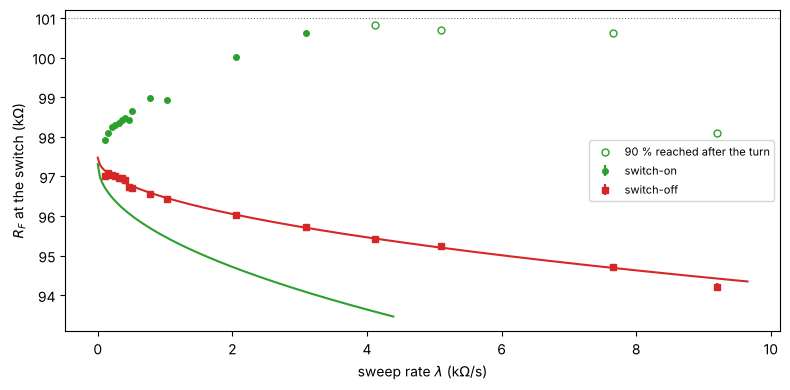

In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.errorbar(g[LAMBDA_COL][valid] / 1e3, g.R_sat_mean[valid] / 1e3, yerr=g.R_sat_std[valid] / 1e3, fmt="o", color="tab:green", ms=4, label="switch-on")
ax.plot(g[LAMBDA_COL][~valid] / 1e3, g.R_sat_mean[~valid] / 1e3, "o", mfc="none", color="tab:green", ms=5, label="90 % reached after the turn")
ax.errorbar(g[LAMBDA_COL] / 1e3, g.R_decay_mean / 1e3, yerr=g.R_decay_std / 1e3, fmt="s", color="tab:red", ms=4, label="switch-off")
L = np.linspace(0, lam.max() * 1.05, 300)
ax.plot(L[L < 4400] / 1e3, results["switch-on"]["f"](L[L < 4400], *results["switch-on"]["p"]) / 1e3, color="tab:green")
ax.plot(L / 1e3, results["switch-off"]["f"](L, *results["switch-off"]["p"]) / 1e3, color="tab:red")
ax.axhline(R_MAX / 1e3, color="gray", ls=":", lw=0.8)
ax.set_xlabel(r"sweep rate $\lambda$ (k$\Omega$/s)"); ax.set_ylabel(r"$R_F$ at the switch (k$\Omega$)"); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(os.path.join(OUT_DIR, "switching_points_fits.png"), dpi=150); plt.show()

## 5. Hysteresis loops (needs the raw recordings)

For each available run: envelope (running maximum of $|V|$ over about 1.5 oscillation periods, or 11 periods for the coarsely sampled slow runs), sampled at the same position in every sweep cycle, averaged over the cycles and normalised to the plateau, against the mid-step resistance.

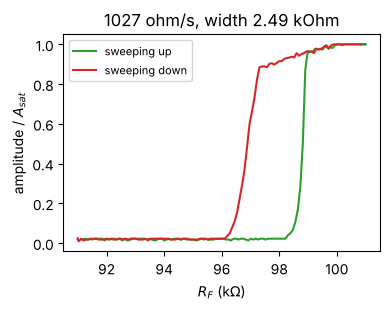

In [6]:
def load3(path):
    df = pd.read_csv(path); t = df.iloc[:, 0].to_numpy(float); v = df.iloc[:, 2].to_numpy(float)
    dt = (t[-1] - t[0]) / (len(t) - 1); return t[0] + dt * np.arange(len(t)), v, dt

def loop(run, nb=120):
    t, v, dt = load3(os.path.join(RAW_FOLDER, run.file))
    n = max(3, int(round((1.5 if dt < 2e-3 else 11) * 0.0138 / dt))) | 1
    env = maximum_filter1d(np.abs(v), n, mode="nearest")
    t0, tau = run.t0_s, run.tau_measured_ms / 1e3; T = 64 * tau
    ncy = int(min(5, np.floor((t[-1] - t0) / T)))
    u = np.linspace(0, 64, 2 * nb, endpoint=False)
    E = np.mean([np.interp(t0 + (c + u / 64) * T, t, env) for c in range(ncy)], axis=0) / run.vmax_mean
    R = R0 + STEP_R * np.clip(np.minimum(u + 0.5, 31 + 32 - 0.5 - u), 0, 31)
    return R[u < 32], E[u < 32], R[u >= 32], E[u >= 32]

avail = [r for _, r in g.iterrows() if r.lambda_nominal in LOOP_RATES and os.path.exists(os.path.join(RAW_FOLDER, r.file))]
if avail:
    fig, axs = plt.subplots(1, len(avail), figsize=(4 * len(avail), 3.2), squeeze=False)
    for ax, r in zip(axs[0], avail):
        Ru, Eu, Rd, Ed = loop(r)
        ax.plot(Ru / 1e3, Eu, color="tab:green", label="sweeping up"); ax.plot(Rd / 1e3, Ed, color="tab:red", label="sweeping down")
        ax.set_title(f"{r[LAMBDA_COL]:.0f} ohm/s, width {(r.R_sat_mean - r.R_decay_mean)/1e3:.2f} kOhm")
        ax.set_xlabel(r"$R_F$ (k$\Omega$)"); ax.set_ylabel(r"amplitude / $A_{sat}$"); ax.legend(fontsize=8)
    fig.tight_layout(); fig.savefig(os.path.join(OUT_DIR, "hysteresis_loops.png"), dpi=150); plt.show()
else:
    print("No raw recordings for LOOP_RATES in RAW_FOLDER: loops skipped.")

## Check against the report

In [7]:
if "Masteranalysis2" in MASTER_CSV:
    s_on, s_off = results["switch-on"], results["switch-off"]
    checks = {
        "Eq. 5.1: R_on = (97313 +/- 60) + (58.1 +/- 2.2) sqrt(lambda)": abs(s_on["Rc"] - 97313) < 1 and abs(s_on["k"] - 58.1) < 0.05 and abs(s_on["k_err"] - 2.2) < 0.05,
        "Eq. 5.2: R_off = (97472 +/- 34) - (31.8 +/- 1.1) sqrt(lambda)": abs(s_off["Rc"] - 97472) < 1 and abs(s_off["k"] - 31.8) < 0.05 and abs(s_off["k_err"] - 1.1) < 0.05,
        "AIC lower by 15 (off) and 6 (on)": round(s_off["dAIC"]) == 15 and round(s_on["dAIC"]) == 6,
        "rms 59 vs 102 ohm (switch-off)": round(s_off["rms_sqrt"]) == 59 and round(s_off["rms_lin"]) == 102,
        "free exponents 0.56 +/- 0.08 and 0.67 +/- 0.08": abs(s_off["a"] - 0.56) < 0.005 and abs(s_on["a"] - 0.67) < 0.005,
        "Eq. 5.3: G_c = 3.07": round(G_c, 2) == 3.07,
        "Eq. 5.4: first critical rate about 4.0 kOhm/s": abs(lam_c1 - 4000) < 50,
        "Lambda_on = 8.3": abs(L_on - 8.3) < 0.05,
    }
    for k, ok in checks.items(): print(("PASS " if ok else "FAIL ") + k)

PASS Eq. 5.1: R_on = (97313 +/- 60) + (58.1 +/- 2.2) sqrt(lambda)
PASS Eq. 5.2: R_off = (97472 +/- 34) - (31.8 +/- 1.1) sqrt(lambda)
PASS AIC lower by 15 (off) and 6 (on)
PASS rms 59 vs 102 ohm (switch-off)
PASS free exponents 0.56 +/- 0.08 and 0.67 +/- 0.08
PASS Eq. 5.3: G_c = 3.07
PASS Eq. 5.4: first critical rate about 4.0 kOhm/s
PASS Lambda_on = 8.3


## Using your own data

Point `MASTER_CSV` at a master table written by notebook 05 for your runs. Adjust the fit ranges so that they include only runs whose switch-on happened on the rising part of the sweep, and set `R_I`, `R_MAX`, `R0`, `STEP_R` and `OMEGA0` for your circuit (for $\omega_0$ you may use the measured frequency: $2\pi\times 72.4$ Hz on our bench gives $k_{\rm off} = 30.85$).